In [1]:
import sw_utils
import numpy as np
import matplotlib.pyplot as plt
# import energyflow as ef
import itertools
%matplotlib inline

dataset_length = 1000
num_dataset = 8
num_particles = 150
num_attr = 4

data_path = '../mini_dataset/'
file_names = ['QCD_1k.npz' ,'HToBB_1k.npz' ,'HToCC_1k.npz','HToGG_1k.npz','HToWW4Q_1k.npz','ZToQQ_1k.npz','WToQQ_1k.npz','TTBar_1k.npz']

all_events = np.zeros((num_dataset * dataset_length, num_particles, num_attr))
all_labels = np.zeros(num_dataset * dataset_length)

event_blocks = np.zeros((num_dataset, dataset_length, num_particles, num_attr))

for i, file in enumerate(file_names):
    f = np.load(data_path + file)
    
    x = f['x']
    y = f['y']
    
    all_events[i*1000:(i+1)*1000] = x
    all_labels[i*1000:(i+1)*1000] = y
    

In [8]:
example_events = all_events[0][:,:3]
print(example_events.shape)

s_repr_padded = sw_utils.compute_spectral_representation(example_events)
# mask = s_repr_padded[:, 1] > 0
# s_repr_padded = s_repr_padded[mask]

mask = example_events[:, 0] > 0
example_events = example_events[mask]
print(example_events.shape)

s_repr_not_padded = sw_utils.compute_spectral_representation(example_events)

print(f"Padded repr shape: {s_repr_padded.shape}")
print(f"Not padded repr: {s_repr_not_padded.shape}")
print(f"Padded repr: {s_repr_padded[-400:]}")
print(f"Not padded repr: {s_repr_not_padded[-50:]}")



(150, 3)
(18, 3)
Padded repr shape: (11176, 2)
Not padded repr: (154, 2)
Padded repr: [[3.156428  0.       ]
 [3.156428  0.       ]
 [3.156428  0.       ]
 [3.156428  0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.       ]
 [3.1580794 0.   

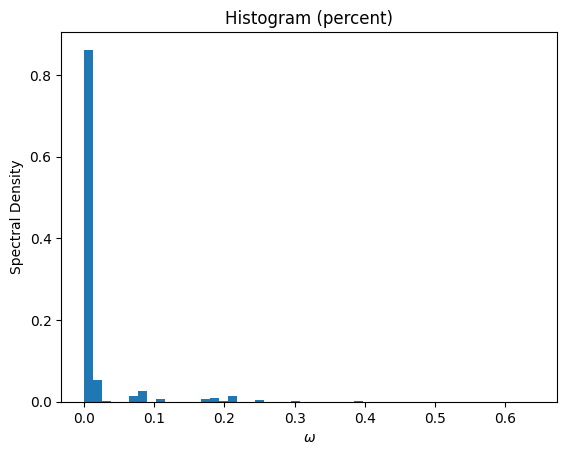

In [6]:
x = s_repr_padded[:,0]
w = s_repr_padded[:,1]

# normalize w so it sums to 100
w_pct = w / w.sum()

plt.hist(x, bins=50, weights=w_pct)
plt.xlabel(r"$\omega$")
plt.ylabel("Spectral Density")
# plt.xlim(0, 0.6)
plt.title("Histogram (percent)")
plt.show()

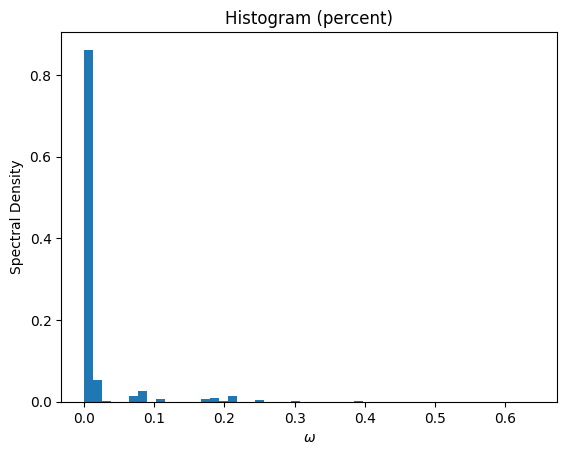

In [7]:
x = s_repr_not_padded[:,0]
w = s_repr_not_padded[:,1]

# normalize w so it sums to 100
w_pct = w / w.sum()

plt.hist(x, bins=50, weights=w_pct)
plt.xlabel(r"$\omega$")
plt.ylabel("Spectral Density")
# plt.xlim(0, 0.6)
plt.title("Histogram (percent)")
plt.show()


In [6]:
s_repr[0, :]

Array([     0.  , 116828.35], dtype=float32)

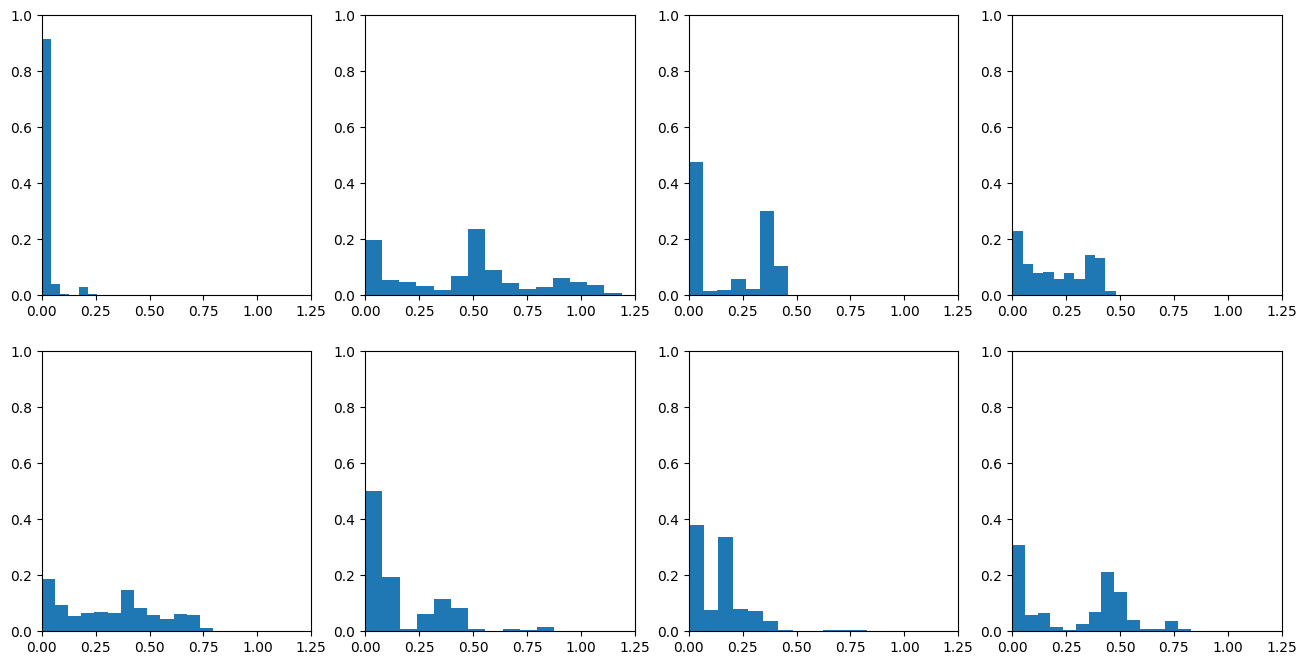

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    example_events = all_events[i*1000][:, :3]
    mask = example_events[:, 0] > 0
    example_events = example_events[mask]
    # print(example_events.shape)
    
    s_repr = sw_utils.compute_spectral_representation(example_events)
    x = s_repr[:, 0]
    w = s_repr[:, 1]
    
    w_pct = w / w.sum()
    ax.hist(x, bins=15, weights=w_pct)
    ax.set_xlim(0, 1.25)
    ax.set_ylim(0, 1)